# Notebook 04: Spatially Aware Predictive Modelling & Interpretation (Phase 6)
**Objectives:**
1. Partition the Zambian Copperbelt study area into **25 km $\times$ 25 km Spatial Blocks** (`StratifiedGroupKFold`) to eliminate spatial autocorrelation data leakage.
2. Train and compare **Logistic Regression** (interpretable linear baseline), **Random Forest**, and **XGBoost**.
3. Quantify the **optimistic bias of naive Random CV** vs. Spatial Block CV across ROC-AUC and PR-AUC.
4. Analyze confusion matrices, Precision-Recall trade-offs (cost of False Positives vs. False Negatives in exploration), and physical feature importances.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.acquisition import generate_zambia_prospectivity_benchmark, load_config
from src.data.cleaning import validate_and_standardize_geodata
from src.features.spatial_features import engineer_geospatial_features
from src.models.spatial_cv import get_spatial_block_splits
from src.models.train_evaluate import (
    evaluate_models_spatial_vs_random,
    extract_feature_importances,
)
from src.visualization.maps import plot_model_performance_and_importance

config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
raw_gdf, faults_gdf = generate_zambia_prospectivity_benchmark(config)
clean_gdf, _ = validate_and_standardize_geodata(raw_gdf, target_crs=config["crs"]["projected_crs"])
feat_gdf, feature_cols = engineer_geospatial_features(clean_gdf, faults_gdf)
modeling_features = [c for c in feature_cols if c != "cu_co_log_ratio"]

## 1. Spatial Block Cross-Validation vs. Random K-Fold Evaluation

In [2]:
block_ids, spatial_splits = get_spatial_block_splits(
    feat_gdf,
    target_col="mineral_occurrence",
    block_size_m=config["validation"]["spatial_block_size_m"],
    n_splits=config["validation"]["n_splits"],
    seed=config["project"]["random_seed"],
)
feat_gdf["spatial_block_id"] = block_ids

metrics_df, oof_spatial_preds, fitted_models = evaluate_models_spatial_vs_random(
    feat_gdf,
    feature_cols=modeling_features,
    target_col="mineral_occurrence",
    spatial_splits=spatial_splits,
    threshold=0.50,
    seed=config["project"]["random_seed"],
)
display(metrics_df)

,model,spatial_roc_auc,random_roc_auc,leakage_roc_inflation,spatial_pr_auc,random_pr_auc,precision,recall,f1_score,brier_score,TP,FP,FN,TN
0,Logistic_Regression,0.7939,0.7996,0.0057,0.3788,0.4015,0.1909,0.6748,0.2976,0.1711,139,589,67,1705
1,Random_Forest,0.7644,0.7783,0.0139,0.3459,0.3897,0.3460,0.3981,0.3702,0.1014,82,155,124,2139
2,XGBoost,0.7543,0.7665,0.0122,0.3352,0.3734,0.4041,0.2864,0.3352,0.0797,59,87,147,2207


## 2. Geoscientific Feature Importance & Diagnostic Curves

,feature,logreg_abs_coef_share,random_forest_importance,xgboost_gain_importance,permutation_pr_auc_drop
0,log10_cu_ppm,0.0640,0.1494,0.1194,0.2824
1,local_cu_halo_log10,0.0501,0.1914,0.1440,0.1730
2,bouguer_gravity_mgal,0.1152,0.0786,0.0502,0.1169
3,mag_residual_nt,0.0323,0.0460,0.0380,0.0715
4,elevation_m,0.0206,0.0463,0.0374,0.0603
5,log10_co_ppm,0.0077,0.0934,0.0478,0.0567
6,radiometric_k_th_ratio,0.0189,0.0401,0.0354,0.0452
7,dist_to_fault_m,0.0094,0.0500,0.0481,0.0355
8,dist_to_redox_contact_m,0.0000,0.0437,0.0451,0.0340
9,mag_anomaly_nt,0.1791,0.0590,0.0490,0.0335


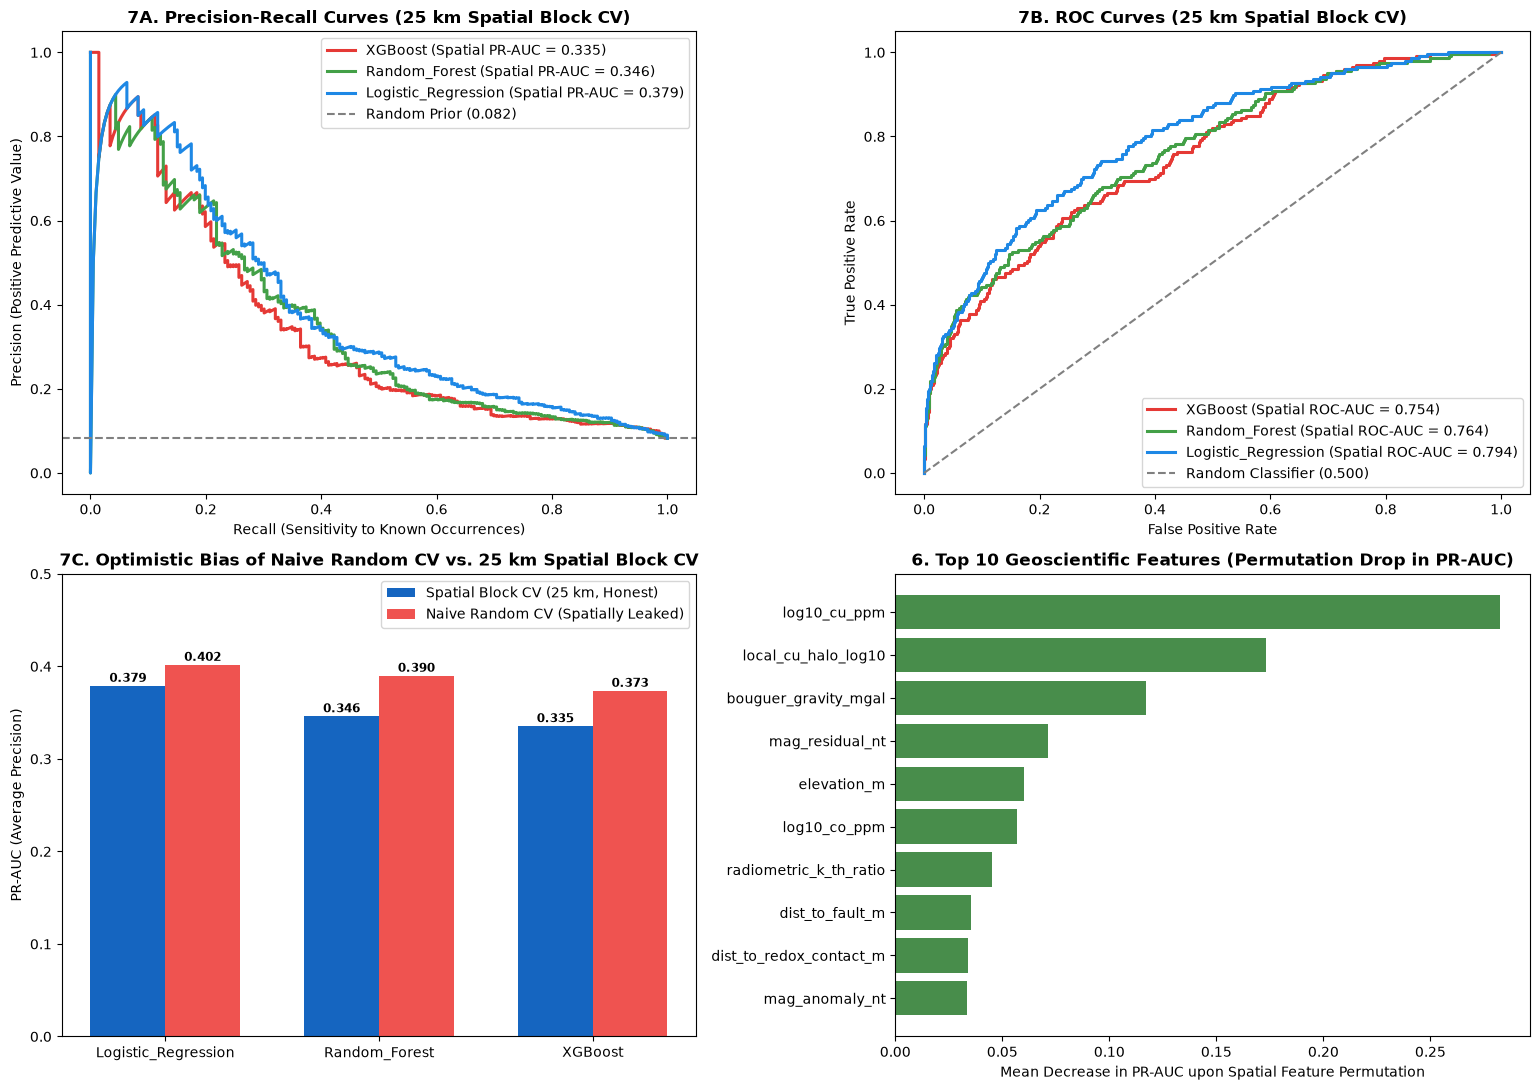

In [3]:
importance_df = extract_feature_importances(
    fitted_models,
    feat_gdf,
    feature_cols=modeling_features,
    target_col="mineral_occurrence",
    seed=config["project"]["random_seed"],
)
display(importance_df.head(12))

fig3 = plot_model_performance_and_importance(
    y_true=feat_gdf["mineral_occurrence"].to_numpy(),
    oof_preds=oof_spatial_preds,
    metrics_df=metrics_df,
    importance_df=importance_df,
    save_path=PROJECT_ROOT / "data" / "processed" / "fig03_model_performance_and_importance.png",
)
plt.show()